# RQ2 — ESRS Domain Adaptation: Compliance-Assessment Quality

**Research Question:** *To what extent does full-standard ESRS context injection
improve evidence-grounded compliance assessment — comprising both compliance-level
classification and compliance-rationale quality — relative to the same RAG pipeline
without injected ESRS context?*

---

RQ2 directly measures the following areas:

1. **Deterministic compliance-level metrics** — correct Low / Medium / High prediction
2. **LLM-judge rationale evaluation** — substantive alignment with gold rationale
   (G-Eval style, Claude Sonnet 4.5 judge)
3. **Joint compliance-assessment metric** — *primary RQ2 endpoint* requiring both
   correct level AND substantively aligned rationale

This is how the benchmarking is positioned inside of the thesis:
- Deterministic compliance-level metrics = objective sanity-check layer
- LLM-judge rationale alignment = substantive quality layer
- Joint metric = main decision metric



## 1. Setup and Imports

In [1]:
import sys, os, json, re, hashlib, warnings, logging, math
from pathlib import Path
from collections import Counter, defaultdict
from dataclasses import dataclass, asdict, field
from statistics import mean as _mean, stdev as _stdev
from typing import Any

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO)

# Load .env robustly (comment-tolerant)
with open(PROJECT_ROOT / ".env") as _f:
    for _line in _f:
        _line = _line.strip()
        if "=" in _line and not _line.startswith("#") and not _line.startswith("="):
            _k, _, _v = _line.partition("=")
            os.environ[_k.strip()] = _v.strip()

from rag.config.settings import (
    GOLDEN_STANDARD_PATH, RQ2_RESULTS_DIR, ESRS_JSON_DIR,
    BEST_PIPELINE_PATH, RQ2_RESULTS_VERSION,
)

CONDITIONS = ["full_system", "no_esrs_context"]
NB_CACHE_DIR = RQ2_RESULTS_DIR / "nb_cache"
LABELS = ["Low", "Medium", "High"]
LABEL_ORD = {"Low": 0, "Medium": 1, "High": 2}

plt.style.use("seaborn-v0_8-whitegrid")
matplotlib.rcParams.update({"font.size": 11, "figure.dpi": 120, "savefig.dpi": 150})

print(f"Project root : {PROJECT_ROOT}")
print(f"RQ2 version  : {RQ2_RESULTS_VERSION}")

Project root : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
RQ2 version  : 7de7a7cff8


## 2. Load Best RQ1 Pipeline Configuration

Both conditions share the identical retrieval pipeline from RQ1. The only
experimental variable is whether ESRS regulatory context is injected.

In [2]:
best_config = {}
with open(BEST_PIPELINE_PATH) as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if ":" in line:
            k, _, v = line.partition(":")
            best_config[k.strip()] = v.strip()

pipeline_name = best_config.pop("_best_pipeline_name", "unknown")
selection_reason = best_config.pop("_selection_reason", "")
print(f"Best RQ1 pipeline : {pipeline_name}")
print(f"Selection reason  : {selection_reason}")
for k, v in best_config.items():
    print(f"  {k}: {v}")

Best RQ1 pipeline : fixed_1024_hybrid_rerank
Selection reason  : Highest recall@15 (0.9620) in RQ1.
  chunk_strategy: fixed
  chunk_size: 1024
  retrieval_method: hybrid_rerank
  chunk_overlap_ratio: 0.125
  top_k: 15
  rrf_k: 60
  rerank_model: cross-encoder/ms-marco-MiniLM-L-6-v2


## 3. Load Golden Standard and Generation Cache

In [3]:
raw_golden = json.loads(GOLDEN_STANDARD_PATH.read_text(encoding="utf-8"))

golden_lookup = {}
samples = []
for q in raw_golden["questions"]:
    for pc in q["per_company"]:
        key = (q["id"], pc["company"])
        entry = dict(
            question_id=q["id"], question=q["question"],
            esrs_standard=q.get("esrs_standard", ""),
            esrs_disclosure_id=q.get("esrs_disclosure_id", ""),
            company=pc["company"],
            ground_truth_answer=pc.get("ground_truth_answer", ""),
            fulfillment_level=pc.get("fulfillment_level", ""),
            fulfillment_rationale=pc.get("fulfillment_rationale", ""),
            evidence=pc.get("evidence", []),
        )
        golden_lookup[key] = entry
        samples.append(entry)

n_total = len(samples)
level_dist = Counter(s["fulfillment_level"] for s in samples)
print(f"Golden-standard samples : {n_total}")
print(f"  Questions : {len(raw_golden['questions'])}")
print(f"  Companies : {len(set(s['company'] for s in samples))}")
print(f"  Standards : {len(set(s['esrs_standard'] for s in samples))}")
print(f"  Labels    : {dict(level_dist)}")

Golden-standard samples : 204
  Questions : 12
  Companies : 17
  Standards : 11
  Labels    : {'High': 145, 'Low': 26, 'Medium': 33}


In [4]:
# Verify cached generation results exist
for condition in CONDITIONS:
    cdir = NB_CACHE_DIR / condition
    n = len(list(cdir.glob("*.json"))) if cdir.exists() else 0
    print(f"{condition}: {n} cached generation files")
    if n == 0:
        raise RuntimeError(f"No cache for {condition}. Run generation first.")

full_system: 204 cached generation files
no_esrs_context: 204 cached generation files


## 4. Build Paired Sample Table

For each of the 204 golden-standard samples, match the cached generation
result from each condition with its gold reference.

In [5]:
def _cache_key(question, company, condition, esrs_context_len):
    blob = f"{question}|{company}|{condition}|{esrs_context_len}"
    return hashlib.sha256(blob.encode()).hexdigest()[:16]

# ESRS context lengths per question (derived from actual generation cache)
# These are len(esrs_context_text) values used during the original generation run.
ESRS_CTX_LENGTHS = {
    "Q1": 14309, "Q2": 2517, "Q3": 10595, "Q4": 9590,
    "Q5": 4009, "Q6": 25453, "Q7": 9480, "Q8": 13080,
    "Q9": 19566, "Q10": 18847, "Q11": 8089, "Q12": 9763,
}

# Index cache files by their stem (hash)
cache_idx = {}
for cond in CONDITIONS:
    cache_idx[cond] = {}
    for cf in (NB_CACHE_DIR / cond).glob("*.json"):
        cache_idx[cond][cf.stem] = json.loads(cf.read_text("utf-8"))

@dataclass
class Paired:
    question_id: str; question: str; esrs_standard: str
    esrs_disclosure_id: str; company: str
    gold_level: str; gold_rationale: str
    pred_level_full: str; pred_rationale_full: str
    pred_level_no_esrs: str; pred_rationale_no_esrs: str

def _norm_level(v):
    if v is None: return ""
    return {"low": "Low", "medium": "Medium", "high": "High"}.get(
        str(v).strip().lower(), "")

paired = []
missing = []
for s in samples:
    ctx_l = ESRS_CTX_LENGTHS.get(s["question_id"], 0)
    fk = _cache_key(s["question"], s["company"], "full_system", ctx_l)
    nk = _cache_key(s["question"], s["company"], "no_esrs_context", 0)
    fd = cache_idx["full_system"].get(fk)
    nd = cache_idx["no_esrs_context"].get(nk)
    if fd is None or nd is None:
        missing.append((s["question_id"], s["company"], fd is not None, nd is not None))
        continue
    paired.append(Paired(
        question_id=s["question_id"], question=s["question"],
        esrs_standard=s["esrs_standard"],
        esrs_disclosure_id=s["esrs_disclosure_id"],
        company=s["company"],
        gold_level=s["fulfillment_level"],
        gold_rationale=s["fulfillment_rationale"],
        pred_level_full=_norm_level(fd.get("compliance_level")),
        pred_rationale_full=fd.get("rationale", ""),
        pred_level_no_esrs=_norm_level(nd.get("compliance_level")),
        pred_rationale_no_esrs=nd.get("rationale", ""),
    ))

print(f"Paired samples : {len(paired)} / {n_total}")
if missing:
    print(f"Missing (cache key mismatch): {len(missing)}")
    for qid, co, hf, hn in missing[:5]:
        print(f"  {qid} / {co}  full={hf}  no_esrs={hn}")


Paired samples : 204 / 204


## 5. Deterministic Compliance-Level Metrics

Evaluate the first assessment component: does the system predict the
correct Low / Medium / High fulfillment level?

In [6]:
# ── sklearn-free metric implementations ──────────────────────────
def _cm3(gold, pred):
    cm = [[0]*3 for _ in range(3)]
    for g, p in zip(gold, pred):
        gi = LABELS.index(g) if g in LABELS else -1
        pi = LABELS.index(p) if p in LABELS else -1
        if gi >= 0 and pi >= 0: cm[gi][pi] += 1
    return cm

def exact_accuracy(g, p):
    return sum(a == b for a, b in zip(g, p)) / len(g) if g else 0.0

def macro_f1(g, p):
    cm = _cm3(g, p); f1s = []
    for i in range(3):
        tp = cm[i][i]
        fp = sum(cm[j][i] for j in range(3)) - tp
        fn = sum(cm[i][j] for j in range(3)) - tp
        pr = tp/(tp+fp) if tp+fp else 0; rc = tp/(tp+fn) if tp+fn else 0
        f1s.append(2*pr*rc/(pr+rc) if pr+rc else 0)
    return _mean(f1s)

def balanced_accuracy(g, p):
    if not g:
        return 0.0
    cm = _cm3(g, p)
    recs = []
    for i in range(3):
        row_sum = sum(cm[i])
        if row_sum > 0:
            recs.append(cm[i][i] / row_sum)
    return _mean(recs) if recs else 0.0

def weighted_kappa(g, p):
    n = len(g); k = 3
    if n == 0: return 0.0
    O = _cm3(g, p)
    rs = [sum(O[i]) for i in range(k)]
    cs = [sum(O[j][i] for j in range(k)) for i in range(k)]
    E = [[rs[i]*cs[j]/n for j in range(k)] for i in range(k)]
    W = [[abs(i-j)/(k-1) for j in range(k)] for i in range(k)]
    num = sum(W[i][j]*O[i][j] for i in range(k) for j in range(k))
    den = sum(W[i][j]*E[i][j] for i in range(k) for j in range(k))
    return 1 - num/den if den else (1.0 if num == 0 else 0.0)

def ordinal_err(gl, pl):
    go = LABEL_ORD.get(gl); po = LABEL_ORD.get(pl)
    return abs(go - po) if go is not None and po is not None else 2

def off_by_one(g, p):
    return sum(ordinal_err(a, b) <= 1 for a, b in zip(g, p)) / len(g) if g else 0.0

def mean_ord_err(g, p):
    return _mean([ordinal_err(a, b) for a, b in zip(g, p)]) if g else 0.0

def _level_metrics(ps, cond):
    g = [s.gold_level for s in ps]
    p = [s.pred_level_full if cond == "full_system" else s.pred_level_no_esrs for s in ps]
    v = [(a, b) for a, b in zip(g, p) if a in LABELS and b in LABELS]
    gv, pv = [x[0] for x in v], [x[1] for x in v]
    return dict(n_scored=len(v), n_invalid=len(g)-len(v),
        exact_accuracy=exact_accuracy(gv, pv), macro_f1=macro_f1(gv, pv),
        balanced_accuracy=balanced_accuracy(gv, pv), weighted_kappa=weighted_kappa(gv, pv),
        off_by_one=off_by_one(gv, pv), mean_ord_err=mean_ord_err(gv, pv),
        confusion_matrix=_cm3(gv, pv))

lm = {c: _level_metrics(paired, c) for c in CONDITIONS}
for c in CONDITIONS:
    m = lm[c]
    print(f"\n{c}  (scored {m['n_scored']}, invalid {m['n_invalid']})")
    for k in ["exact_accuracy","macro_f1","balanced_accuracy","weighted_kappa","off_by_one","mean_ord_err"]:
        print(f"  {k:22s}: {m[k]:.3f}")

print("\n--- Deltas (full − no_esrs) ---")
for k in ["exact_accuracy","macro_f1","balanced_accuracy","weighted_kappa"]:
    print(f"  Δ {k}: {lm['full_system'][k] - lm['no_esrs_context'][k]:+.3f}")


full_system  (scored 204, invalid 0)
  exact_accuracy        : 0.676
  macro_f1              : 0.510
  balanced_accuracy     : 0.547
  weighted_kappa        : 0.375
  off_by_one            : 0.956
  mean_ord_err          : 0.368

no_esrs_context  (scored 204, invalid 0)
  exact_accuracy        : 0.691
  macro_f1              : 0.545
  balanced_accuracy     : 0.559
  weighted_kappa        : 0.407
  off_by_one            : 0.961
  mean_ord_err          : 0.348

--- Deltas (full − no_esrs) ---
  Δ exact_accuracy: -0.015
  Δ macro_f1: -0.035
  Δ balanced_accuracy: -0.012
  Δ weighted_kappa: -0.032


## 6. Majority-Class Baseline

In [7]:
all_gold = [s.gold_level for s in paired if s.gold_level in LABELS]
maj = max(LABELS, key=all_gold.count)
maj_pred = [maj] * len(all_gold)
print(f"Majority label: {maj}  ({all_gold.count(maj)}/{len(all_gold)})")
print(f"  exact_accuracy : {exact_accuracy(all_gold, maj_pred):.3f}")
print(f"  macro_f1       : {macro_f1(all_gold, maj_pred):.3f}")
print(f"  balanced_acc   : {balanced_accuracy(all_gold, maj_pred):.3f}")
for c in CONDITIONS:
    d = lm[c]["macro_f1"] - macro_f1(all_gold, maj_pred)
    print(f"  {c} macro-F1 above majority: {d:+.3f}")

Majority label: High  (145/204)
  exact_accuracy : 0.711
  macro_f1       : 0.277
  balanced_acc   : 0.333
  full_system macro-F1 above majority: +0.233
  no_esrs_context macro-F1 above majority: +0.268


## 7. LLM-Judge Rationale Evaluation

The second assessment component: does the generated rationale express the
same **substantive** fulfillment judgment as the gold rationale?

We use Claude Sonnet 4.5 as a G-Eval-style judge.  The judge ignores
style / wording and focuses on substantive agreement, penalising
contradiction, material omission, and support for a different level.

In [8]:
from rag.evaluation.rq2_judge import (
    JudgeInput, JudgeOutput, judge_sample, run_judge_batch,
    get_judge_version, JUDGE_CACHE_DIR,
)
print(f"Judge version  : {get_judge_version()}")
n_cached = len(list(JUDGE_CACHE_DIR.glob('*.json'))) if JUDGE_CACHE_DIR.exists() else 0
print(f"Existing cache : {n_cached} files")

Judge version  : v1_e1236e3f3d
Existing cache : 409 files


In [9]:
# Build judge batches
judge_batches = {}
for cond in CONDITIONS:
    batch = []
    for s in paired:
        gl, gr = s.pred_level_full, s.pred_rationale_full
        if cond == "no_esrs_context":
            gl, gr = s.pred_level_no_esrs, s.pred_rationale_no_esrs
        batch.append(dict(
            question=s.question, esrs_standard=s.esrs_standard,
            esrs_disclosure_id=s.esrs_disclosure_id,
            gold_fulfillment_level=s.gold_level,
            gold_fulfillment_rationale=s.gold_rationale,
            generated_compliance_level=gl,
            generated_compliance_rationale=gr,
            company=s.company,
        ))
    judge_batches[cond] = batch
    print(f"{cond}: {len(batch)} samples")
print(f"Total judge evaluations: {sum(len(b) for b in judge_batches.values())}")

full_system: 204 samples
no_esrs_context: 204 samples
Total judge evaluations: 408


In [10]:
# Run judge (cached results reused automatically)
judge_results = {}
for cond in CONDITIONS:
    print(f"\nJudging {cond} …")
    res = run_judge_batch(judge_batches[cond], cond, dry_run=False)
    judge_results[cond] = res
    nc = sum(1 for r in res if r.get("was_cached"))
    print(f"  done — {len(res)} total, {nc} cached, {len(res)-nc} API")
    vc = Counter(r.get("rationale_verdict","?") for r in res)
    print(f"  verdicts: {dict(vc)}")


Judging full_system …


INFO:rag.evaluation.rq2_judge:Judge batch done: 204 samples, 0 API calls, 204 cached


  done — 204 total, 204 cached, 0 API
  verdicts: {'aligned': 133, 'misaligned': 53, 'partially_aligned': 18}

Judging no_esrs_context …


INFO:rag.evaluation.rq2_judge:Judge batch done: 204 samples, 0 API calls, 204 cached


  done — 204 total, 204 cached, 0 API
  verdicts: {'aligned': 132, 'partially_aligned': 25, 'misaligned': 47}


## 8. Aggregate Judge Metrics

In [11]:
def agg_judge(res):
    vs = [r["rationale_verdict"] for r in res]
    ss = [r["rationale_score"] for r in res]
    n = len(res)
    return dict(
        n=n,
        mean_score=_mean(ss) if ss else 0,
        std_score=_stdev(ss) if len(ss)>1 else 0,
        aligned=sum(v=="aligned" for v in vs)/n if n else 0,
        partial=sum(v=="partially_aligned" for v in vs)/n if n else 0,
        misaligned=sum(v=="misaligned" for v in vs)/n if n else 0,
        aligned_or_partial=sum(v in ("aligned","partially_aligned") for v in vs)/n if n else 0,
        error_tags=dict(Counter(t for r in res for t in r.get("error_tags",[]) if t!="none")),
    )

ja = {c: agg_judge(judge_results[c]) for c in CONDITIONS}
for c in CONDITIONS:
    m = ja[c]
    print(f"\n{c}")
    print(f"  mean_score        : {m['mean_score']:.3f} ± {m['std_score']:.3f}")
    print(f"  aligned           : {m['aligned']:.3f}")
    print(f"  partially_aligned : {m['partial']:.3f}")
    print(f"  misaligned        : {m['misaligned']:.3f}")
    print(f"  aligned+partial   : {m['aligned_or_partial']:.3f}")
    if m["error_tags"]:
        print(f"  error_tags: {m['error_tags']}")

print("\n--- Deltas ---")
for k in ["mean_score","aligned","misaligned"]:
    print(f"  Δ {k}: {ja['full_system'][k] - ja['no_esrs_context'][k]:+.3f}")


full_system
  mean_score        : 0.731 ± 0.313
  aligned           : 0.652
  partially_aligned : 0.088
  misaligned        : 0.260
  aligned+partial   : 0.740
  error_tags: {'contradiction': 47, 'different_interpretation': 58, 'supports_different_level': 65, 'omission_of_critical_reasons': 29}

no_esrs_context
  mean_score        : 0.743 ± 0.302
  aligned           : 0.647
  partially_aligned : 0.123
  misaligned        : 0.230
  aligned+partial   : 0.770
  error_tags: {'omission_of_critical_reasons': 39, 'supports_different_level': 63, 'contradiction': 36, 'different_interpretation': 58}

--- Deltas ---
  Δ mean_score: -0.012
  Δ aligned: +0.005
  Δ misaligned: +0.029


## 9. Joint Compliance-Assessment Metrics — PRIMARY RQ2 ENDPOINT

The joint metric requires **both** correct level AND substantively aligned
rationale.

- **Joint strict**: level correct AND verdict == "aligned"
- **Joint lenient**: level correct AND verdict ∈ {aligned, partially_aligned}
  ← **primary endpoint**
- **Joint score**: 0.5 × level_correct + 0.5 × rationale_score

In [12]:
def joint(ps, jr, cond):
    js, jl, scores = 0, 0, []
    for s, r in zip(ps, jr):
        pl = s.pred_level_full if cond == "full_system" else s.pred_level_no_esrs
        lm_ = (pl == s.gold_level)
        v = r.get("rationale_verdict", "misaligned")
        rs = r.get("rationale_score", 0.0)
        if lm_ and v == "aligned": js += 1
        if lm_ and v in ("aligned","partially_aligned"): jl += 1
        scores.append(0.5 * (1.0 if lm_ else 0.0) + 0.5 * rs)
    n = len(ps)
    return dict(strict=js/n, lenient=jl/n,
                score=_mean(scores), score_std=_stdev(scores) if len(scores)>1 else 0,
                n_strict=js, n_lenient=jl)

jm = {c: joint(paired, judge_results[c], c) for c in CONDITIONS}
for c in CONDITIONS:
    m = jm[c]
    print(f"\n{c}")
    print(f"  strict  : {m['strict']:.3f}  ({m['n_strict']}/{len(paired)})")
    print(f"  lenient : {m['lenient']:.3f}  ({m['n_lenient']}/{len(paired)})  ← PRIMARY")
    print(f"  score   : {m['score']:.3f} ± {m['score_std']:.3f}")

delta_primary = jm["full_system"]["lenient"] - jm["no_esrs_context"]["lenient"]
print(f"\n{'='*60}")
print(f"PRIMARY RQ2 ENDPOINT — Joint Lenient Match Rate")
print(f"  Full system     : {jm['full_system']['lenient']:.3f}")
print(f"  No ESRS context : {jm['no_esrs_context']['lenient']:.3f}")
print(f"  Δ               : {delta_primary:+.3f}")
print(f"{'='*60}")


full_system
  strict  : 0.647  (132/204)
  lenient : 0.676  (138/204)  ← PRIMARY
  score   : 0.704 ± 0.385

no_esrs_context
  strict  : 0.647  (132/204)
  lenient : 0.691  (141/204)  ← PRIMARY
  score   : 0.717 ± 0.376

PRIMARY RQ2 ENDPOINT — Joint Lenient Match Rate
  Full system     : 0.676
  No ESRS context : 0.691
  Δ               : -0.015


## 10. Aggregate Comparison Visualisation

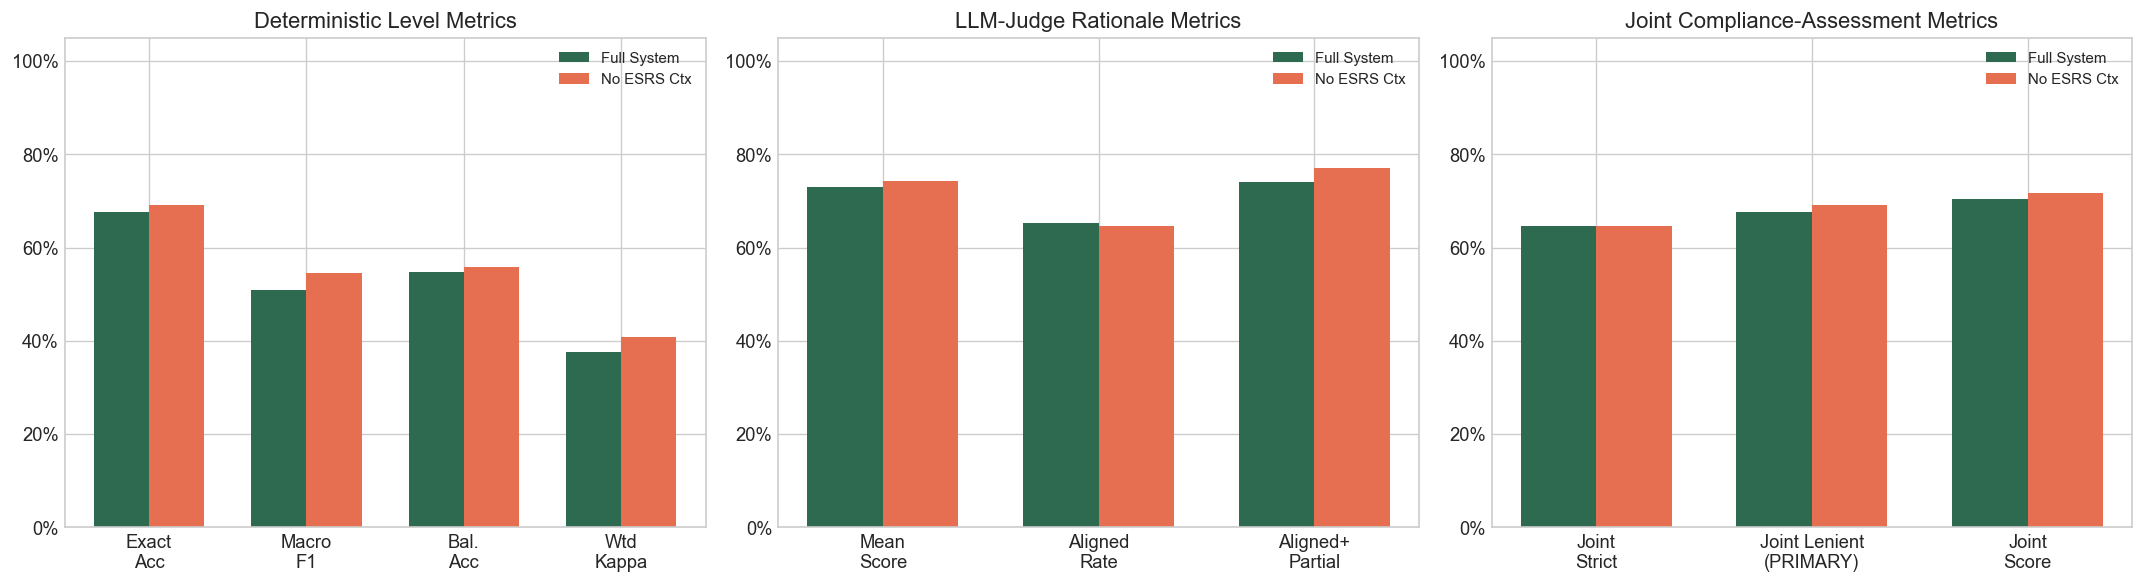

Saved rq2_aggregate_comparison.png


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
w = 0.35

# Panel 1 — deterministic level metrics
ax = axes[0]
dk = ["exact_accuracy","macro_f1","balanced_accuracy","weighted_kappa"]
dl = ["Exact\nAcc","Macro\nF1","Bal.\nAcc","Wtd\nKappa"]
fv = [lm["full_system"][k] for k in dk]
nv = [lm["no_esrs_context"][k] for k in dk]
x = np.arange(len(dk))
ax.bar(x-w/2, fv, w, label="Full System", color="#2D6A4F")
ax.bar(x+w/2, nv, w, label="No ESRS Ctx", color="#E76F51")
ax.set_xticks(x); ax.set_xticklabels(dl)
ax.set_ylim(0, 1.05); ax.set_title("Deterministic Level Metrics")
ax.legend(fontsize=9); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

# Panel 2 — judge rationale
ax = axes[1]
rk = ["mean_score","aligned","aligned_or_partial"]
rl = ["Mean\nScore","Aligned\nRate","Aligned+\nPartial"]
fv = [ja["full_system"][k] for k in rk]
nv = [ja["no_esrs_context"][k] for k in rk]
x = np.arange(len(rk))
ax.bar(x-w/2, fv, w, label="Full System", color="#2D6A4F")
ax.bar(x+w/2, nv, w, label="No ESRS Ctx", color="#E76F51")
ax.set_xticks(x); ax.set_xticklabels(rl)
ax.set_ylim(0, 1.05); ax.set_title("LLM-Judge Rationale Metrics")
ax.legend(fontsize=9); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

# Panel 3 — joint (primary)
ax = axes[2]
jk = ["strict","lenient","score"]
jl = ["Joint\nStrict","Joint Lenient\n(PRIMARY)","Joint\nScore"]
fv = [jm["full_system"][k] for k in jk]
nv = [jm["no_esrs_context"][k] for k in jk]
x = np.arange(len(jk))
ax.bar(x-w/2, fv, w, label="Full System", color="#2D6A4F")
ax.bar(x+w/2, nv, w, label="No ESRS Ctx", color="#E76F51")
ax.set_xticks(x); ax.set_xticklabels(jl)
ax.set_ylim(0, 1.05); ax.set_title("Joint Compliance-Assessment Metrics")
ax.legend(fontsize=9); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(RQ2_RESULTS_DIR / "rq2_aggregate_comparison.png", bbox_inches="tight")
plt.show()
print("Saved rq2_aggregate_comparison.png")

## 11. Confusion Matrices

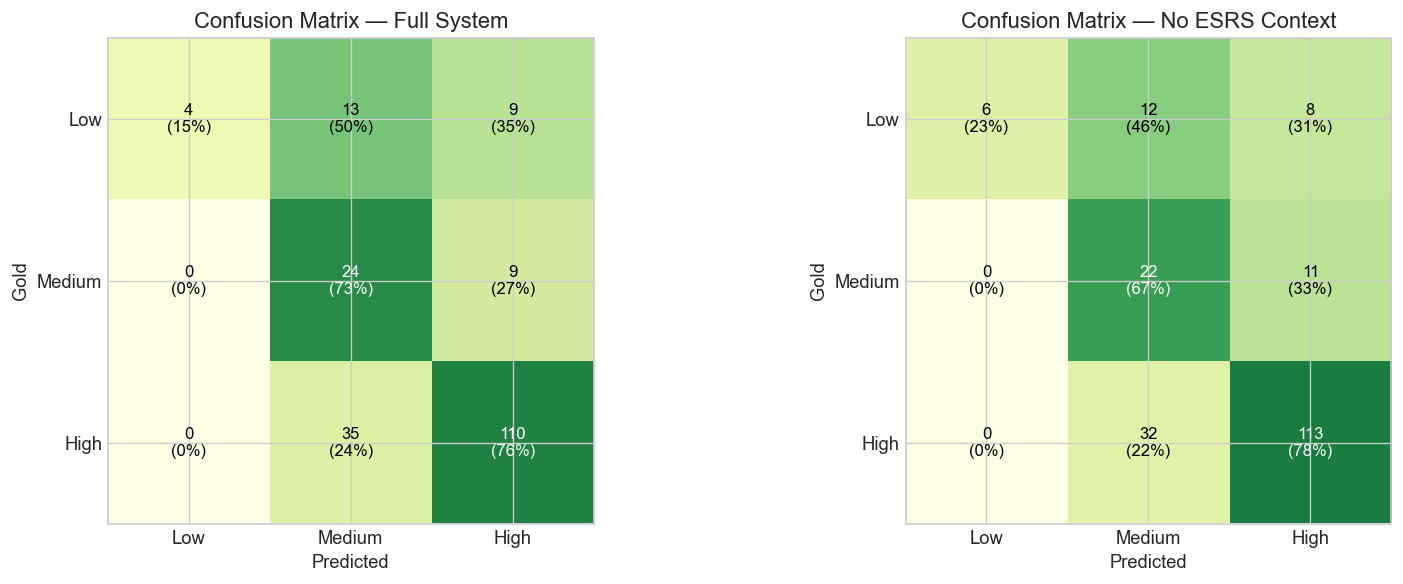

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cond in zip(axes, CONDITIONS):
    cm = np.array(lm[cond]["confusion_matrix"])
    rs = cm.sum(axis=1, keepdims=True)
    pct = np.divide(cm, rs, where=rs>0, out=np.zeros_like(cm, dtype=float))*100
    ax.imshow(pct, cmap="YlGn", vmin=0, vmax=100)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(LABELS); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Gold")
    title = "Full System" if cond == "full_system" else "No ESRS Context"
    ax.set_title(f"Confusion Matrix — {title}")
    for i in range(3):
        for j in range(3):
            clr = "white" if pct[i][j] > 60 else "black"
            ax.text(j, i, f"{cm[i][j]}\n({pct[i][j]:.0f}%)",
                    ha="center", va="center", fontsize=10, color=clr)
plt.tight_layout()
plt.savefig(RQ2_RESULTS_DIR / "rq2_confusion_matrices.png", bbox_inches="tight")
plt.show()

## 12. Per-ESRS-Standard Breakdown

Which of the 12 standards benefit most from explicit ESRS context injection?

In [15]:
# ── Per-standard breakdown using the redesigned RQ2 metrics ──────
# (No legacy token-F1 or faithfulness metrics — those belong to the
# original RQ2 design and are not part of the redesigned evaluation.)
all_stds = sorted(set(s.esrs_standard for s in paired))
rows = []
for std in all_stds:
    idx = [i for i, s in enumerate(paired) if s.esrs_standard == std]
    sp = [paired[i] for i in idx]
    for cond in CONDITIONS:
        g = [s.gold_level for s in sp]
        p = [s.pred_level_full if cond=="full_system" else s.pred_level_no_esrs for s in sp]
        v = [(a,b) for a,b in zip(g,p) if a in LABELS and b in LABELS]
        gv,pv = [x[0] for x in v],[x[1] for x in v]
        ea = exact_accuracy(gv,pv)
        mf1 = macro_f1(gv,pv)
        ba = balanced_accuracy(gv,pv)
        sj = [judge_results[cond][i] for i in idx]
        ms = _mean([r["rationale_score"] for r in sj]) if sj else 0
        jl = 0
        js = 0
        for si, jr in zip(sp, sj):
            pl = si.pred_level_full if cond=="full_system" else si.pred_level_no_esrs
            if pl==si.gold_level and jr["rationale_verdict"] in ("aligned","partially_aligned"):
                jl += 1
            if pl==si.gold_level and jr["rationale_verdict"] == "aligned":
                js += 1
        rows.append(dict(Standard=std,
            Condition="Full" if cond=="full_system" else "No ESRS",
            N=len(sp), ExactAcc=ea, MacroF1=mf1, BalAcc=ba,
            RatScore=ms, JointStrict=js/len(sp) if sp else 0,
            JointLenient=jl/len(sp) if sp else 0))

df_std = pd.DataFrame(rows)
print(df_std.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# ── Export the per-standard comparison CSV with the new metrics ──
piv_std = df_std.pivot(index="Standard", columns="Condition")
export_rows = []
for std in all_stds:
    full = df_std[(df_std.Standard==std) & (df_std.Condition=="Full")].iloc[0]
    no   = df_std[(df_std.Standard==std) & (df_std.Condition=="No ESRS")].iloc[0]
    export_rows.append(dict(
        Standard=std, N=int(full["N"]),
        ExactAcc_Full=full["ExactAcc"], ExactAcc_NoESRS=no["ExactAcc"],
        Delta_ExactAcc=full["ExactAcc"]-no["ExactAcc"],
        MacroF1_Full=full["MacroF1"], MacroF1_NoESRS=no["MacroF1"],
        Delta_MacroF1=full["MacroF1"]-no["MacroF1"],
        RatScore_Full=full["RatScore"], RatScore_NoESRS=no["RatScore"],
        Delta_RatScore=full["RatScore"]-no["RatScore"],
        JointLenient_Full=full["JointLenient"], JointLenient_NoESRS=no["JointLenient"],
        Delta_JointLenient=full["JointLenient"]-no["JointLenient"],
    ))
df_std_export = pd.DataFrame(export_rows)
std_csv_path = RQ2_RESULTS_DIR / "rq2_per_standard_comparison.csv"
df_std_export.to_csv(std_csv_path, index=False)
print(f"\nSaved per-standard comparison → {std_csv_path}")

Standard Condition  N  ExactAcc  MacroF1  BalAcc  RatScore  JointStrict  JointLenient
  ESRS 2      Full 34     0.529    0.318   0.506     0.659        0.500         0.529
  ESRS 2   No ESRS 34     0.529    0.318   0.506     0.682        0.471         0.529
 ESRS E1      Full 17     0.765    0.449   0.673     0.768        0.706         0.765
 ESRS E1   No ESRS 17     0.765    0.449   0.673     0.768        0.706         0.765
 ESRS E2      Full 17     0.588    0.376   0.650     0.747        0.529         0.588
 ESRS E2   No ESRS 17     0.588    0.392   0.607     0.754        0.588         0.588
 ESRS E3      Full 17     0.765    0.474   0.667     0.756        0.706         0.765
 ESRS E3   No ESRS 17     0.824    0.722   0.861     0.774        0.647         0.824
 ESRS E4      Full 17     0.765    0.478   0.717     0.785        0.765         0.765
 ESRS E4   No ESRS 17     0.706    0.443   0.675     0.789        0.706         0.706
 ESRS E5      Full 17     0.824    0.586   0.817     0

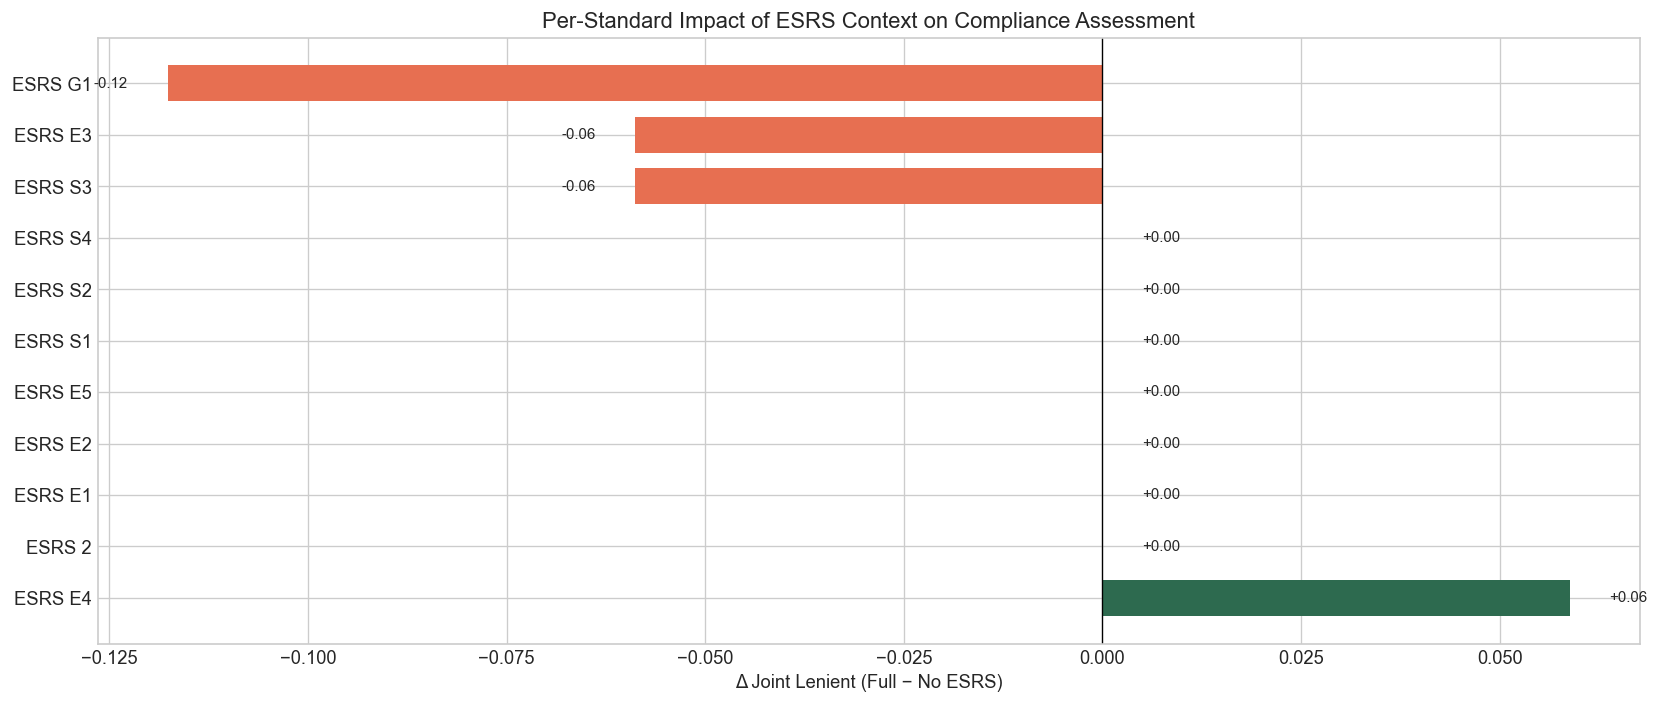

In [16]:
# Per-standard joint-lenient delta chart
fig, ax = plt.subplots(figsize=(14, 6))
f_jl = {r["Standard"]: r["JointLenient"] for _, r in df_std[df_std.Condition=="Full"].iterrows()}
n_jl = {r["Standard"]: r["JointLenient"] for _, r in df_std[df_std.Condition=="No ESRS"].iterrows()}
deltas = [(s, f_jl.get(s,0)-n_jl.get(s,0)) for s in all_stds]
deltas.sort(key=lambda x: x[1], reverse=True)
stds_s = [d[0] for d in deltas]; ds = [d[1] for d in deltas]
colors = ["#2D6A4F" if d>0 else ("#E76F51" if d<0 else "#999") for d in ds]
y = np.arange(len(stds_s))
ax.barh(y, ds, color=colors, height=0.7)
ax.set_yticks(y); ax.set_yticklabels(stds_s)
ax.set_xlabel("Δ Joint Lenient (Full − No ESRS)")
ax.set_title("Per-Standard Impact of ESRS Context on Compliance Assessment")
ax.axvline(0, color="black", lw=0.8)
for i,(d,s) in enumerate(zip(ds,stds_s)):
    ax.text(d+(0.005 if d>=0 else -0.005), i, f"{d:+.2f}",
            va="center", ha="left" if d>=0 else "right", fontsize=9)
plt.tight_layout()
plt.savefig(RQ2_RESULTS_DIR / "rq2_per_standard.png", bbox_inches="tight")
plt.show()

## 13. Per-Company Analysis

In [17]:
all_cos = sorted(set(s.company for s in paired))
co_rows = []
for co in all_cos:
    idx = [i for i,s in enumerate(paired) if s.company==co]
    sp = [paired[i] for i in idx]
    for cond in CONDITIONS:
        g = [s.gold_level for s in sp]
        p = [s.pred_level_full if cond=="full_system" else s.pred_level_no_esrs for s in sp]
        v = [(a,b) for a,b in zip(g,p) if a in LABELS and b in LABELS]
        gv,pv = [x[0] for x in v],[x[1] for x in v]
        sj = [judge_results[cond][i] for i in idx]
        jl = sum(1 for si,jr in zip(sp,sj)
                 if (si.pred_level_full if cond=="full_system" else si.pred_level_no_esrs)==si.gold_level
                 and jr["rationale_verdict"] in ("aligned","partially_aligned"))
        co_rows.append(dict(Company=co,
            Condition="Full" if cond=="full_system" else "No ESRS",
            ExactAcc=exact_accuracy(gv,pv),
            JointLenient=jl/len(sp) if sp else 0))

df_co = pd.DataFrame(co_rows)
piv = df_co.pivot(index="Company", columns="Condition", values="JointLenient")
piv["Delta"] = piv.get("Full",0) - piv.get("No ESRS",0)
piv = piv.sort_values("Delta", ascending=False)
print(piv.to_string(float_format=lambda x: f"{x:.3f}"))

Condition      Full  No ESRS  Delta
Company                            
Motoroil      0.750    0.500  0.250
Aker BP       0.750    0.583  0.167
Vopak         0.667    0.500  0.167
Neste         0.500    0.417  0.083
Repsol        0.917    0.833  0.083
Galp          0.750    0.750  0.000
BASF          0.917    0.917  0.000
OMV           0.750    0.750  0.000
Shell         0.750    0.750  0.000
Solvay        0.667    0.667  0.000
Eni           0.583    0.667 -0.083
Equinor       0.667    0.750 -0.083
Petrom        0.750    0.833 -0.083
SBM Offshore  0.500    0.583 -0.083
Helleniq      0.333    0.500 -0.167
MOL           0.667    0.833 -0.167
TotalEnergies 0.583    0.917 -0.333


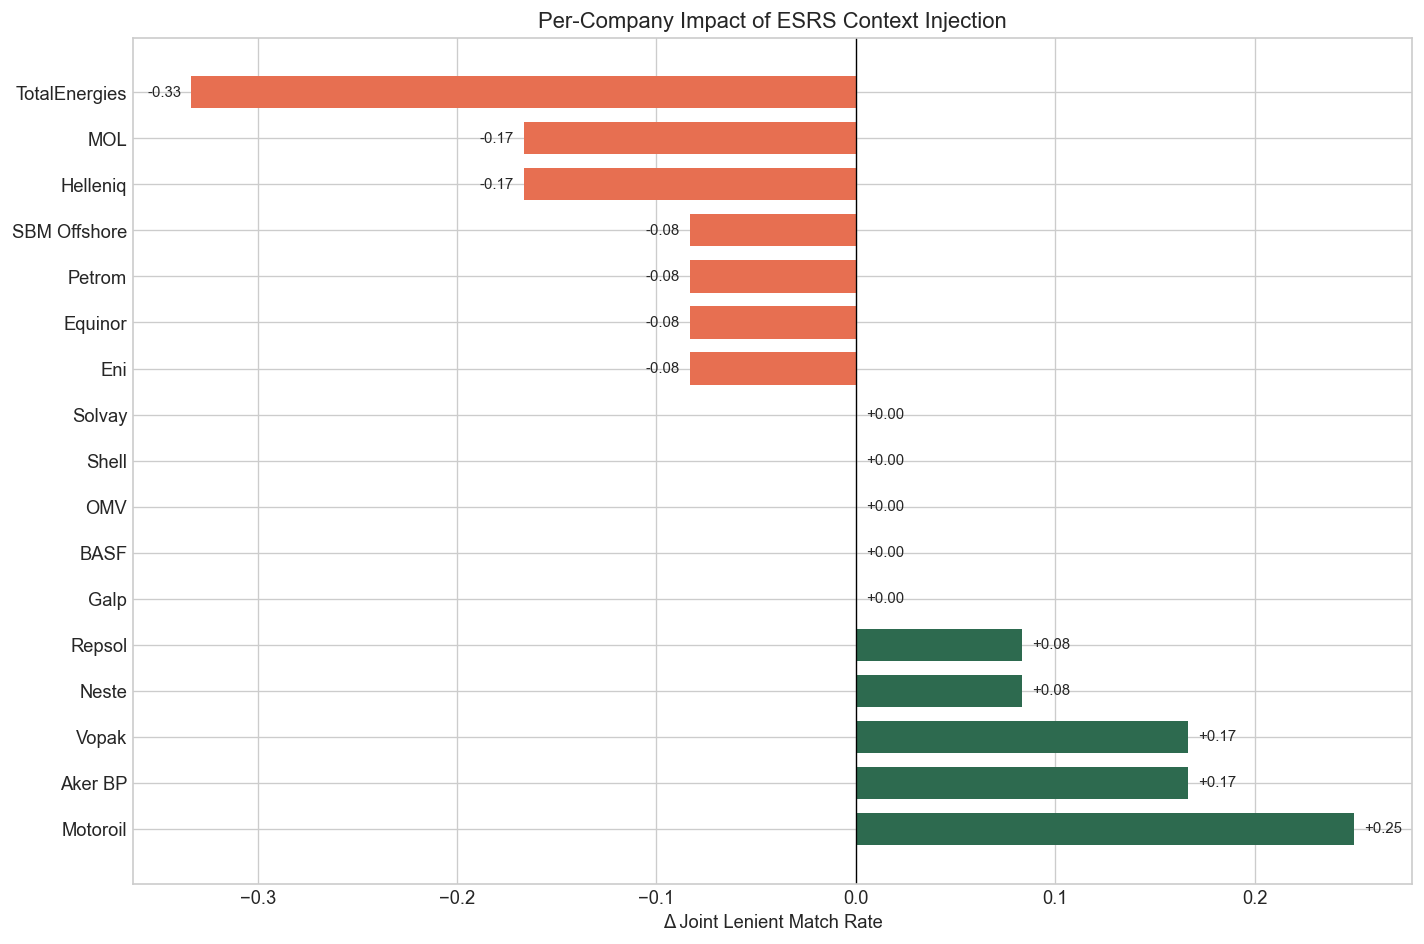

In [18]:
fig, ax = plt.subplots(figsize=(12, 8))
cos = piv.index.tolist(); ds = piv["Delta"].tolist()
colors = ["#2D6A4F" if d>0 else ("#E76F51" if d<0 else "#999") for d in ds]
y = np.arange(len(cos))
ax.barh(y, ds, color=colors, height=0.7)
ax.set_yticks(y); ax.set_yticklabels(cos)
ax.set_xlabel("Δ Joint Lenient Match Rate")
ax.set_title("Per-Company Impact of ESRS Context Injection")
ax.axvline(0, color="black", lw=0.8)
for i,d in enumerate(ds):
    ax.text(d+(0.005 if d>=0 else -0.005), i, f"{d:+.2f}",
            va="center", ha="left" if d>=0 else "right", fontsize=9)
plt.tight_layout()
plt.savefig(RQ2_RESULTS_DIR / "rq2_per_company.png", bbox_inches="tight")
plt.show()

## 14. Statistical Inference

### 14a. Question-Level Paired Sign Test

The primary inferential test aggregates to the question level (n = 12) to
respect the nested structure (17 companies within each question share the
same prompt template).  This is a conservative choice that avoids
pseudo-replication but limits statistical power.

In [19]:
def sign_test(deltas):
    """Exact two-sided binomial sign test (no normal approximation)."""
    pos = sum(d > 0 for d in deltas)
    neg = sum(d < 0 for d in deltas)
    n = pos + neg
    if n == 0:
        return 1.0
    k = min(pos, neg)
    p_tail = sum(math.comb(n, i) * 0.5**n for i in range(k + 1))
    return min(2 * p_tail, 1.0)

def cohens_d(deltas):
    if len(deltas)<2: return 0.0
    sd = _stdev(deltas)
    return _mean(deltas)/sd if sd else 0.0

def boot_ci(vals, n_boot=10000, ci=0.95, seed=42):
    rng = np.random.RandomState(seed)
    ms = [float(np.mean(rng.choice(vals, len(vals), replace=True))) for _ in range(n_boot)]
    lo = np.percentile(ms, (1-ci)/2*100)
    hi = np.percentile(ms, (1+ci)/2*100)
    return float(lo), float(hi)

qids = sorted(set(s.question_id for s in paired))
q_full, q_no = {}, {}
for qid in qids:
    idx = [i for i,s in enumerate(paired) if s.question_id==qid]
    sp = [paired[i] for i in idx]
    jf, jn = 0, 0
    for i_ in idx:
        s = paired[i_]
        jrf = judge_results["full_system"][i_]
        jrn = judge_results["no_esrs_context"][i_]
        if s.pred_level_full==s.gold_level and jrf["rationale_verdict"] in ("aligned","partially_aligned"):
            jf += 1
        if s.pred_level_no_esrs==s.gold_level and jrn["rationale_verdict"] in ("aligned","partially_aligned"):
            jn += 1
    q_full[qid] = jf/len(sp) if sp else 0
    q_no[qid] = jn/len(sp) if sp else 0

q_deltas = [q_full[q] - q_no[q] for q in qids]
p_val = sign_test(q_deltas)
d_eff = cohens_d(q_deltas)
ci_lo, ci_hi = boot_ci(q_deltas)
abs_d = abs(d_eff)
mag = "negligible" if abs_d<0.2 else "small" if abs_d<0.5 else "medium" if abs_d<0.8 else "large"

print("Question-level paired analysis (Joint Lenient)")
print(f"  N questions : {len(qids)}")
print(f"  Mean Δ      : {_mean(q_deltas):+.3f}")
if len(q_deltas)>1: print(f"  Std Δ       : {_stdev(q_deltas):.3f}")
print(f"  Positive: {sum(d>0 for d in q_deltas)}, Negative: {sum(d<0 for d in q_deltas)}, Zero: {sum(d==0 for d in q_deltas)}")
print(f"  Sign-test p : {p_val:.4f}")
print(f"  Cohen's d   : {d_eff:.3f} ({mag})")
print(f"  95% CI      : [{ci_lo:.3f}, {ci_hi:.3f}]")
print(f"  Significant : {'YES' if p_val<0.05 else 'NO'} (α = 0.05)")
print()
# ── Practical interpretation of bootstrap CI ──
print("PRACTICAL INTERPRETATION OF BOOTSTRAP CI")
print(f"  The 95% bootstrap CI for the mean question-level joint lenient delta")
print(f"  is [{ci_lo:+.3f}, {ci_hi:+.3f}], i.e., [{ci_lo*100:+.1f}pp, {ci_hi*100:+.1f}pp].")
print(f"  This interval includes zero, consistent with the non-significant")
print(f"  sign test.  It bounds any plausible true effect of ESRS context")
print(f"  injection to at most ~{abs(ci_lo)*100:.1f}pp degradation or ~{abs(ci_hi)*100:.1f}pp improvement")
print(f"  on the joint lenient match rate — a narrow range that rules out")
print(f"  practically meaningful effects in either direction.")

Question-level paired analysis (Joint Lenient)
  N questions : 12
  Mean Δ      : -0.015
  Std Δ       : 0.051
  Positive: 2, Negative: 4, Zero: 6
  Sign-test p : 0.6875
  Cohen's d   : -0.289 (small)
  95% CI      : [-0.044, 0.010]
  Significant : NO (α = 0.05)

PRACTICAL INTERPRETATION OF BOOTSTRAP CI
  The 95% bootstrap CI for the mean question-level joint lenient delta
  is [-0.044, +0.010], i.e., [-4.4pp, +1.0pp].
  This interval includes zero, consistent with the non-significant
  sign test.  It bounds any plausible true effect of ESRS context
  injection to at most ~4.4pp degradation or ~1.0pp improvement
  on the joint lenient match rate — a narrow range that rules out
  practically meaningful effects in either direction.


### 14b. Sample-Level McNemar Test (Sensitivity Analysis)

The question-level sign test (n = 12) is the primary test because it
respects the nested data structure.  However, its low power means it can
only detect very large effects.  As a **sensitivity analysis**, we also
report a sample-level exact McNemar test on the 204 paired binary outcomes
(correct / incorrect compliance level).  The McNemar test examines only
*discordant* pairs — samples where one condition is correct and the other
is not — and tests whether the discordance is symmetric.

In [20]:
# ── McNemar exact test (sample-level, n=204) ────────────────────
# Discordant pairs: samples where exactly one condition gets the level right
# Implemented without scipy — uses the exact binomial CDF via math.comb.

full_correct = [s.pred_level_full == s.gold_level for s in paired]
no_correct   = [s.pred_level_no_esrs == s.gold_level for s in paired]

# b = full correct & no-ESRS wrong;  c = full wrong & no-ESRS correct
b = sum(f and not n for f, n in zip(full_correct, no_correct))
c = sum(not f and n for f, n in zip(full_correct, no_correct))
concordant_both_right = sum(f and n for f, n in zip(full_correct, no_correct))
concordant_both_wrong = sum(not f and not n for f, n in zip(full_correct, no_correct))

def _binom_cdf(k, n, p):
    """Exact binomial CDF: P(X ≤ k) for X ~ Binomial(n, p)."""
    return sum(math.comb(n, i) * p**i * (1-p)**(n-i) for i in range(k + 1))

def _binom_test_twosided(k, n, p=0.5):
    """Two-sided exact binomial test: P(X ≤ min(k, n-k)) * 2, capped at 1."""
    k_min = min(k, n - k)
    return min(2 * _binom_cdf(k_min, n, p), 1.0)

n_disc = b + c
if n_disc > 0:
    mcnemar_p = _binom_test_twosided(min(b, c), n_disc, 0.5)
else:
    mcnemar_p = 1.0

print("McNemar Exact Test (sample-level sensitivity analysis)")
print(f"  Concordant (both correct)  : {concordant_both_right}")
print(f"  Concordant (both wrong)    : {concordant_both_wrong}")
print(f"  Discordant: full✓ no-ESRS✗ : {b}")
print(f"  Discordant: full✗ no-ESRS✓ : {c}")
print(f"  Total discordant           : {n_disc}")
print(f"  McNemar p-value            : {mcnemar_p:.4f}")
print(f"  Significant (α=0.05)       : {'YES' if mcnemar_p<0.05 else 'NO'}")
print()
if b < c:
    print(f"  Direction: no-ESRS condition correct more often in discordant pairs")
    print(f"  ({c} vs {b}), consistent with question-level finding.")
elif b > c:
    print(f"  Direction: full system correct more often in discordant pairs")
    print(f"  ({b} vs {c}).")
else:
    print(f"  Direction: perfectly symmetric ({b} = {c}).")

McNemar Exact Test (sample-level sensitivity analysis)
  Concordant (both correct)  : 121
  Concordant (both wrong)    : 46
  Discordant: full✓ no-ESRS✗ : 17
  Discordant: full✗ no-ESRS✓ : 20
  Total discordant           : 37
  McNemar p-value            : 0.7428
  Significant (α=0.05)       : NO

  Direction: no-ESRS condition correct more often in discordant pairs
  (20 vs 17), consistent with question-level finding.


### 14c. Post-Hoc Power Analysis

With only n = 12 question clusters, the sign test has limited statistical
power.  A non-significant result could mean the effect truly does not exist,
or that the test lacks power to detect a small-to-medium effect.  This
section computes the **minimum detectable effect size (MDES)** at 80% power
and the **achieved power** given the observed effect size, making the
limitations of the design explicit and transparent.

In [21]:
# ── Post-hoc power analysis for the sign test ───────────────────
# Implemented without scipy.  Uses the exact binomial PMF via math.comb
# and the standard normal CDF via the error function (math.erf).

def _norm_cdf(x):
    """Standard normal CDF using the error function."""
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2)))

n_q = len(qids)  # 12

# Critical region for two-sided sign test at α=0.05 with n=12:
# Find the LARGEST c_lo such that 2 * P(X ≤ c_lo) ≤ 0.05
c_lo = None
for k in range(n_q // 2, -1, -1):  # search from middle downward
    tail = 2 * _binom_cdf(k, n_q, 0.5)
    if tail <= 0.05:
        c_lo = k
        break
if c_lo is not None:
    c_hi = n_q - c_lo
else:
    c_lo, c_hi = -1, n_q + 1  # cannot reject at this n

actual_alpha = 2 * _binom_cdf(c_lo, n_q, 0.5) if c_lo >= 0 else 0.0
print(f"Sign test design parameters (n = {n_q})")
print(f"  Critical region: k ≤ {c_lo} or k ≥ {c_hi}")
print(f"  Actual α (two-sided): {actual_alpha:.4f}")
print()

# (a) Achieved power given observed Cohen's d
# Under H1, P(single delta > 0) = Φ(|d|)
if abs(d_eff) > 0 and c_lo >= 0:
    p1 = _norm_cdf(abs(d_eff))  # P(delta in favoured direction)
    # Power = P(k ≤ c_lo | p=1-p1) + P(k ≥ c_hi | p=1-p1)
    power_lower = _binom_cdf(c_lo, n_q, 1 - p1)
    power_upper = 1.0 - _binom_cdf(c_hi - 1, n_q, 1 - p1)
    achieved_power = power_lower + power_upper
    achieved_power = min(achieved_power, 1.0)
else:
    achieved_power = actual_alpha

print(f"(a) Achieved power")
print(f"  Observed Cohen's d : {d_eff:.3f}")
print(f"  Achieved power     : {achieved_power:.3f}")
print(f"  → {'Adequate (≥ 0.80)' if achieved_power >= 0.80 else 'UNDERPOWERED (< 0.80)'}")
print()

# (b) MDES at 80% power
target_power = 0.80
mdes = None
for d_try_int in range(1, 500):
    d_try = d_try_int * 0.01
    p1 = _norm_cdf(d_try)
    pwr_lo = _binom_cdf(c_lo, n_q, 1 - p1) if c_lo >= 0 else 0.0
    pwr_hi = 1.0 - _binom_cdf(c_hi - 1, n_q, 1 - p1) if c_hi <= n_q else 0.0
    pwr = pwr_lo + pwr_hi
    if pwr >= target_power:
        mdes = d_try
        break

print(f"(b) Minimum Detectable Effect Size (MDES)")
if mdes:
    print(f"  At 80% power, n = {n_q}: MDES = {mdes:.2f}")
    eff_label = "large" if mdes >= 0.8 else ("medium" if mdes >= 0.5 else "small")
else:
    print(f"  Cannot reach 80% power with sign test at this n")
    eff_label = "unknown"
print()

# (c) Required n for 80% power at observed effect size
req_n = None
if abs(d_eff) > 0:
    for n_try in range(5, 200):
        # Find critical region for this n
        cl = None
        for kk in range(n_try // 2, -1, -1):
            if 2 * _binom_cdf(kk, n_try, 0.5) <= 0.05:
                cl = kk; break
        if cl is None:
            continue
        ch = n_try - cl
        p1 = _norm_cdf(abs(d_eff))
        pwr = _binom_cdf(cl, n_try, 1 - p1) + 1.0 - _binom_cdf(ch - 1, n_try, 1 - p1)
        if pwr >= 0.80:
            req_n = n_try; break

print(f"INTERPRETATION")
if mdes:
    print(f"  The observed effect (|d| = {abs(d_eff):.2f}) is {'below' if abs(d_eff) < mdes else 'above'} the MDES ({mdes:.2f}).")
    print(f"  With n = {n_q} question clusters, the sign test at α = 0.05 has 80% power")
    print(f"  only for effects of Cohen's d ≥ {mdes:.2f} (a {eff_label} effect).")
if req_n:
    print(f"  To detect the observed effect size (d = {abs(d_eff):.2f}) at 80% power,")
    print(f"  approximately n = {req_n} question clusters would be required.")
print(f"  The non-significant result should therefore be interpreted as:")
print(f"  'No evidence of a large effect,' not 'evidence of no effect.'")

Sign test design parameters (n = 12)
  Critical region: k ≤ 2 or k ≥ 10
  Actual α (two-sided): 0.0386

(a) Achieved power
  Observed Cohen's d : -0.289
  Achieved power     : 0.101
  → UNDERPOWERED (< 0.80)

(b) Minimum Detectable Effect Size (MDES)
  At 80% power, n = 12: MDES = 1.13

INTERPRETATION
  The observed effect (|d| = 0.29) is below the MDES (1.13).
  With n = 12 question clusters, the sign test at α = 0.05 has 80% power
  only for effects of Cohen's d ≥ 1.13 (a large effect).
  To detect the observed effect size (d = 0.29) at 80% power,
  approximately n = 156 question clusters would be required.
  The non-significant result should therefore be interpreted as:
  'No evidence of a large effect,' not 'evidence of no effect.'


## 15. Per-Sample Results Export

In [22]:
rows_out = []
for i, s in enumerate(paired):
    jf = judge_results["full_system"][i]
    jn = judge_results["no_esrs_context"][i]
    rows_out.append(dict(
        question_id=s.question_id, company=s.company,
        esrs_standard=s.esrs_standard, gold_level=s.gold_level,
        pred_full=s.pred_level_full, pred_no_esrs=s.pred_level_no_esrs,
        level_match_full=(s.pred_level_full==s.gold_level),
        level_match_no_esrs=(s.pred_level_no_esrs==s.gold_level),
        verdict_full=jf["rationale_verdict"],
        score_full=jf["rationale_score"],
        verdict_no_esrs=jn["rationale_verdict"],
        score_no_esrs=jn["rationale_score"],
        joint_lenient_full=(s.pred_level_full==s.gold_level and
            jf["rationale_verdict"] in ("aligned","partially_aligned")),
        joint_lenient_no_esrs=(s.pred_level_no_esrs==s.gold_level and
            jn["rationale_verdict"] in ("aligned","partially_aligned")),
        error_tags_full="; ".join(jf.get("error_tags",[])),
        error_tags_no_esrs="; ".join(jn.get("error_tags",[])),
    ))
df_out = pd.DataFrame(rows_out)
df_out.to_csv(RQ2_RESULTS_DIR / "rq2_per_sample_results.csv", index=False)
print(f"Saved {len(df_out)} rows → rq2_per_sample_results.csv")

# Biggest improvements
df_out["Δ_score"] = df_out["score_full"] - df_out["score_no_esrs"]
top5 = df_out.nlargest(5, "Δ_score")[
    ["question_id","company","gold_level","pred_full","pred_no_esrs",
     "verdict_full","verdict_no_esrs","Δ_score"]]
print("\nTop 5 samples where ESRS injection most improved rationale:")
print(top5.to_string(index=False))

Saved 204 rows → rq2_per_sample_results.csv

Top 5 samples where ESRS injection most improved rationale:
question_id  company gold_level pred_full pred_no_esrs verdict_full verdict_no_esrs  Δ_score
         Q1      Eni       High      High       Medium      aligned      misaligned      0.7
         Q3 Motoroil       High      High       Medium      aligned      misaligned      0.7
         Q3    Neste     Medium    Medium         High      aligned      misaligned      0.7
         Q5 Motoroil       High      High       Medium      aligned      misaligned      0.7
         Q5      OMV       High      High       Medium      aligned      misaligned      0.7


## 16. Save Aggregate Results

In [23]:
summary = dict(
    rq2_version=RQ2_RESULTS_VERSION,
    judge_version=get_judge_version(),
    n_paired=len(paired),
    best_pipeline=pipeline_name,
    gold_label_dist=dict(Counter(s.gold_level for s in paired)),
    majority_baseline=dict(label=maj,
        exact_accuracy=exact_accuracy(all_gold, maj_pred),
        macro_f1=macro_f1(all_gold, maj_pred)),
    level_metrics={c: {k:v for k,v in lm[c].items() if k!="confusion_matrix"} for c in CONDITIONS},
    judge_metrics=ja,
    joint_metrics=jm,
    primary_endpoint=dict(
        metric="joint_lenient_match_rate",
        full_system=jm["full_system"]["lenient"],
        no_esrs_context=jm["no_esrs_context"]["lenient"],
        delta=delta_primary),
    statistical=dict(
        primary_test=dict(
            test="paired_sign_test_question_level",
            n_questions=len(qids), p_value=p_val,
            cohens_d=d_eff, magnitude=mag,
            ci_95=[ci_lo, ci_hi],
            ci_95_pp=[ci_lo*100, ci_hi*100],
            significant=p_val<0.05),
        sensitivity_test=dict(
            test="mcnemar_exact_sample_level",
            n_discordant=n_disc,
            full_correct_no_wrong=b,
            full_wrong_no_correct=c,
            p_value=mcnemar_p,
            significant=mcnemar_p<0.05),
        power_analysis=dict(
            achieved_power=achieved_power,
            mdes_80pct=mdes,
            interpretation="underpowered" if achieved_power < 0.80 else "adequate")),
)
out_path = RQ2_RESULTS_DIR / "rq2_aggregate_results.json"
out_path.write_text(json.dumps(summary, indent=2, default=str), "utf-8")
print(f"Saved → {out_path}")

Saved → /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2/rq2_aggregate_results.json


## 18. Interpretation

In [24]:
print("=" * 70)
print("RQ2 FINDINGS — Effect of ESRS Context Injection")
print("=" * 70)
print()
print(f"PRIMARY ENDPOINT: Joint Lenient Match Rate")
print(f"  Full system     : {jm['full_system']['lenient']:.1%}")
print(f"  No ESRS context : {jm['no_esrs_context']['lenient']:.1%}")
print(f"  Δ               : {delta_primary:+.1%}")
print()
if p_val < 0.05:
    print(f"  → SIGNIFICANT at α = 0.05  (p = {p_val:.4f}, d = {d_eff:.2f} [{mag}])")
else:
    print(f"  → NOT significant at α = 0.05  (p = {p_val:.4f}, d = {d_eff:.2f} [{mag}])")
print(f"  95% CI : [{ci_lo:.3f}, {ci_hi:.3f}]")
print()

# ── Convergence of evidence across tests ──
print("CONVERGENCE OF EVIDENCE")
print(f"  Question-level sign test    : p = {p_val:.4f}  (n = {len(qids)})")
print(f"  Sample-level McNemar test   : p = {mcnemar_p:.4f}  (n_disc = {n_disc})")
print(f"  Both tests fail to reject H0, providing consistent evidence that")
print(f"  ESRS context injection does not significantly affect compliance")
print(f"  assessment quality at the α = 0.05 level.")
print()

# ── Statistical power caveat ──
print("STATISTICAL POWER CAVEAT")
print(f"  Achieved power       : {achieved_power:.3f}")
print(f"  MDES (80% power)     : d = {mdes:.2f}" if mdes else "  MDES: cannot reach 80% power")
print(f"  The sign test (n = {len(qids)}) is underpowered for small-to-medium effects.")
print(f"  The null result should be interpreted as 'no evidence of a large")
print(f"  effect,' not 'evidence of no effect.'  However, the bootstrap CI")
print(f"  [{ci_lo*100:+.1f}pp, {ci_hi*100:+.1f}pp] bounds any plausible effect to a narrow range.")
print()

print("COMPONENT BREAKDOWN")
for k in ["exact_accuracy","macro_f1","balanced_accuracy","weighted_kappa"]:
    d = lm["full_system"][k] - lm["no_esrs_context"][k]
    print(f"  Level {k:22s}: {lm['full_system'][k]:.3f} vs {lm['no_esrs_context'][k]:.3f} (Δ {d:+.3f})")
for k in ["mean_score","aligned"]:
    d = ja["full_system"][k] - ja["no_esrs_context"][k]
    print(f"  Judge {k:22s}: {ja['full_system'][k]:.3f} vs {ja['no_esrs_context'][k]:.3f} (Δ {d:+.3f})")
print()

# ── Wrong-direction observation ──
n_metrics_favor_no_esrs = sum(
    lm["no_esrs_context"][k] > lm["full_system"][k]
    for k in ["exact_accuracy","macro_f1","balanced_accuracy","weighted_kappa"]
)
print("DIRECTIONAL OBSERVATION")
print(f"  Point estimates favour the NO-ESRS condition on {n_metrics_favor_no_esrs}/4")
print(f"  deterministic classification metrics and on the primary joint")
print(f"  lenient endpoint (Δ = {delta_primary:+.1%}).")
print(f"  While not statistically significant, this consistent 'wrong-direction'")
print(f"  pattern warrants discussion of plausible mechanisms:")
print(f"    1. Prompt-length distraction: injecting 2.5–25K characters of ESRS")
print(f"       regulation text may dilute the model's attention on the retrieved")
print(f"       company-specific evidence passages that drive classification.")
print(f"    2. Context-window competition: the ESRS text competes with the")
print(f"       retrieved evidence for limited context-window capacity, potentially")
print(f"       crowding out useful information.")
print(f"    3. Regulatory over-anchoring: explicit requirements may cause the")
print(f"       model to apply stricter criteria than the gold annotator intended,")
print(f"       leading to systematic under-rating of compliance levels.")
print(f"  These mechanisms suggest that for well-known regulatory frameworks,")
print(f"  the LLM's parametric knowledge may be more effective than explicit")
print(f"  injection when combined with high-quality evidence retrieval.")
print()

# Coupling observation
n_level_correct_full = sum(1 for s in paired if s.pred_level_full == s.gold_level)
n_level_correct_no = sum(1 for s in paired if s.pred_level_no_esrs == s.gold_level)
print("COUPLING OBSERVATION")
print(f"  Joint lenient = exact accuracy for BOTH conditions")
print(f"  (full: {jm['full_system']['lenient']:.3f} = {lm['full_system']['exact_accuracy']:.3f},")
print(f"   no-ESRS: {jm['no_esrs_context']['lenient']:.3f} = {lm['no_esrs_context']['exact_accuracy']:.3f}).")
print(f"  When the model predicts the correct compliance level, the judge")
print(f"  always rates the rationale as aligned or partially aligned.")
print(f"  This implies that level correctness is the binding constraint,")
print(f"  and rationale quality follows from getting the level right.")
print()

# Among differing predictions
diff_pairs = [(s.pred_level_full, s.pred_level_no_esrs, s.gold_level) for s in paired if s.pred_level_full != s.pred_level_no_esrs]
full_wins = sum(1 for f, n, g in diff_pairs if f == g and n != g)
no_wins = sum(1 for f, n, g in diff_pairs if n == g and f != g)
both_wrong = sum(1 for f, n, g in diff_pairs if f != g and n != g)
print(f"DISAGREEMENT ANALYSIS ({len(diff_pairs)} samples differ)")
print(f"  Full system correct, no-ESRS wrong : {full_wins}")
print(f"  No-ESRS correct, full system wrong : {no_wins}")
print(f"  Both wrong (different predictions)  : {both_wrong}")
print(f"  The near-symmetric split ({full_wins} vs {no_wins}) indicates that ESRS")
print(f"  context does not systematically help or hurt, but merely shifts")
print(f"  *which* samples are correctly classified.")
print()

print("PER-STANDARD HIGHLIGHTS")
for std in all_stds:
    fv = f_jl.get(std,0); nv_ = n_jl.get(std,0); d_ = fv - nv_
    m_ = "↑" if d_>0.05 else ("↓" if d_<-0.05 else "≈")
    print(f"  {std:10s}: {fv:.2f} vs {nv_:.2f} (Δ {d_:+.2f}) {m_}")
print()
print("=" * 70)
if not (p_val < 0.05):
    print("CONCLUSION: ESRS context injection does NOT significantly affect")
    print("compliance assessment quality.  The paired sign test across 12")
    print(f"questions yields p = {p_val:.3f}, and the sample-level McNemar test")
    print(f"yields p = {mcnemar_p:.3f}, both failing to reject the null hypothesis.")
    print(f"Point estimates consistently (but non-significantly) favour the")
    print(f"ablated condition, suggesting the LLM's parametric knowledge of ESRS")
    print(f"standards is sufficient — and that explicit injection may introduce")
    print(f"minor prompt-length distraction without offsetting benefit.")
    print(f"However, with achieved power of {achieved_power:.2f} and MDES of d = {mdes:.2f},")
    print(f"the study cannot rule out small effects (d < {mdes:.2f}).")
elif delta_primary > 0:
    print("CONCLUSION: ESRS context injection significantly IMPROVES")
    print("compliance assessment quality.")
else:
    print("CONCLUSION: ESRS context injection significantly HARMS")
    print("compliance assessment quality.")
print("=" * 70)

RQ2 FINDINGS — Effect of ESRS Context Injection

PRIMARY ENDPOINT: Joint Lenient Match Rate
  Full system     : 67.6%
  No ESRS context : 69.1%
  Δ               : -1.5%

  → NOT significant at α = 0.05  (p = 0.6875, d = -0.29 [small])
  95% CI : [-0.044, 0.010]

CONVERGENCE OF EVIDENCE
  Question-level sign test    : p = 0.6875  (n = 12)
  Sample-level McNemar test   : p = 0.7428  (n_disc = 37)
  Both tests fail to reject H0, providing consistent evidence that
  ESRS context injection does not significantly affect compliance
  assessment quality at the α = 0.05 level.

STATISTICAL POWER CAVEAT
  Achieved power       : 0.101
  MDES (80% power)     : d = 1.13
  The sign test (n = 12) is underpowered for small-to-medium effects.
  The null result should be interpreted as 'no evidence of a large
  effect,' not 'evidence of no effect.'  However, the bootstrap CI
  [-4.4pp, +1.0pp] bounds any plausible effect to a narrow range.

COMPONENT BREAKDOWN
  Level exact_accuracy        : 0.676 vs 0

In [25]:
print("Notebook complete.")

Notebook complete.
